In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/comment-category-prediction-challenge/Sample.csv
/kaggle/input/comment-category-prediction-challenge/train.csv
/kaggle/input/comment-category-prediction-challenge/test.csv


In [2]:
train = pd.read_csv("/kaggle/input/comment-category-prediction-challenge/train.csv")
test = pd.read_csv("/kaggle/input/comment-category-prediction-challenge/test.csv")

In [3]:
print(train.shape)
print(test.shape)

(198000, 15)
(102000, 14)


In [4]:
print(train.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 198000 entries, 0 to 197999
Data columns (total 15 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   created_date  198000 non-null  object
 1   post_id       198000 non-null  int64 
 2   emoticon_1    198000 non-null  int64 
 3   emoticon_2    198000 non-null  int64 
 4   emoticon_3    198000 non-null  int64 
 5   upvote        198000 non-null  int64 
 6   downvote      198000 non-null  int64 
 7   if_1          198000 non-null  int64 
 8   if_2          198000 non-null  int64 
 9   race          52577 non-null   object
 10  religion      52577 non-null   object
 11  gender        52577 non-null   object
 12  disability    198000 non-null  bool  
 13  comment       197999 non-null  object
 14  label         198000 non-null  int64 
dtypes: bool(1), int64(9), object(5)
memory usage: 21.3+ MB
None


In [5]:
train = train.drop(columns=['created_date','post_id'])
print(train.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 198000 entries, 0 to 197999
Data columns (total 13 columns):
 #   Column      Non-Null Count   Dtype 
---  ------      --------------   ----- 
 0   emoticon_1  198000 non-null  int64 
 1   emoticon_2  198000 non-null  int64 
 2   emoticon_3  198000 non-null  int64 
 3   upvote      198000 non-null  int64 
 4   downvote    198000 non-null  int64 
 5   if_1        198000 non-null  int64 
 6   if_2        198000 non-null  int64 
 7   race        52577 non-null   object
 8   religion    52577 non-null   object
 9   gender      52577 non-null   object
 10  disability  198000 non-null  bool  
 11  comment     197999 non-null  object
 12  label       198000 non-null  int64 
dtypes: bool(1), int64(8), object(4)
memory usage: 18.3+ MB
None


In [6]:
print(train.isnull().sum())

emoticon_1         0
emoticon_2         0
emoticon_3         0
upvote             0
downvote           0
if_1               0
if_2               0
race          145423
religion      145423
gender        145423
disability         0
comment            1
label              0
dtype: int64


In [7]:
train['race'] = train['race'].fillna("unknown")
train['religion'] = train['religion'].fillna("unknown")
train['race'] = train['race'].fillna("unknown")

In [8]:
train['disability'] = train['disability'].astype(int)

In [9]:
train[['upvote','downvote','if_1','if_2','disability',
    'emoticon_1','emoticon_2','emoticon_3']].describe()


,upvote,downvote,if_1,if_2,disability,emoticon_1,emoticon_2,emoticon_3
count,198000.000000,198000.000000,198000.000000,198000.000000,198000.000000,198000.000000,198000.000000,198000.000000
mean,2.607975,0.666394,1.906152,7.956212,0.013854,0.279768,0.048338,0.121071
std,5.054763,2.044335,25.635752,14.839464,0.116883,1.023234,0.258477,0.481013
min,0.000000,0.000000,0.000000,3.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,4.000000,0.000000,0.000000,0.000000,0.000000
50%,1.000000,0.000000,0.000000,6.000000,0.000000,0.000000,0.000000,0.000000
75%,3.000000,1.000000,4.000000,10.000000,0.000000,0.000000,0.000000,0.000000
max,201.000000,107.000000,1860.000000,1833.000000,1.000000,47.000000,11.000000,17.000000


In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

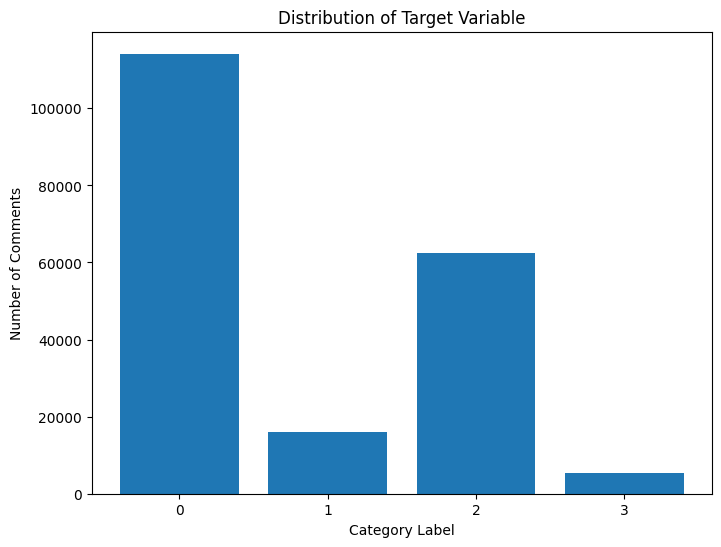

In [11]:
label_count = train['label'].value_counts().sort_index()
plt.figure(figsize=(8,6))
plt.bar(label_count.index.astype(str),label_count.values)
plt.xlabel('Category Label')
plt.ylabel('Number of Comments')
plt.title('Distribution of Target Variable')
plt.show()

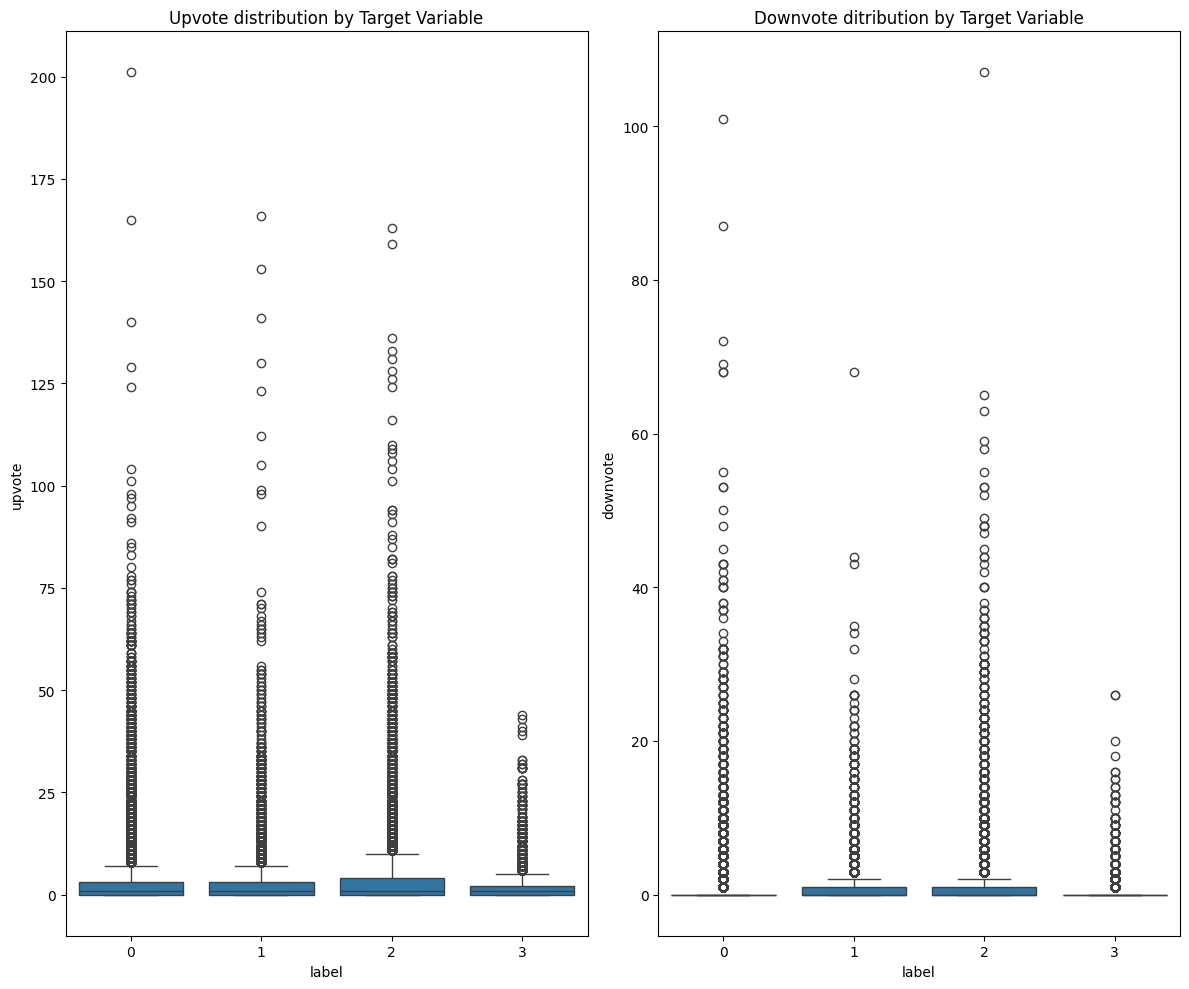

In [12]:
fig,axes = plt.subplots(1,2,figsize=(12,10))
sns.boxplot(data=train,x='label',y='upvote',ax=axes[0])
axes[0].set_title("Upvote distribution by Target Variable")
sns.boxplot(data=train,x='label',y='downvote',ax=axes[1])
axes[1].set_title("Downvote ditribution by Target Variable")
plt.tight_layout()
plt.show()

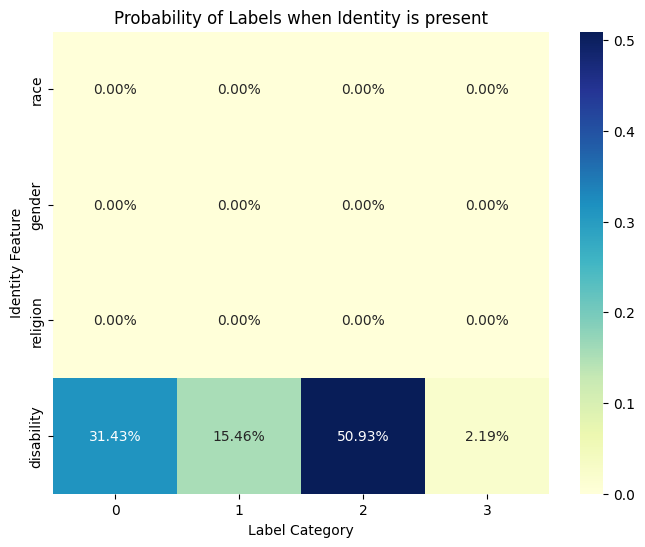

In [13]:
data = []
identities = ['race','gender','religion','disability']

for col in identities:
    probs = train[train[col]==1]['label'].value_counts(normalize=True).sort_index()
    data.append(probs)

prob_df = pd.DataFrame(data,index=identities).fillna(0)

plt.figure(figsize=(8,6))
sns.heatmap(prob_df,annot=True,cmap='YlGnBu',fmt='.2%')
plt.title("Probability of Labels when Identity is present")
plt.xlabel('Label Category')
plt.ylabel('Identity Feature')
plt.show()

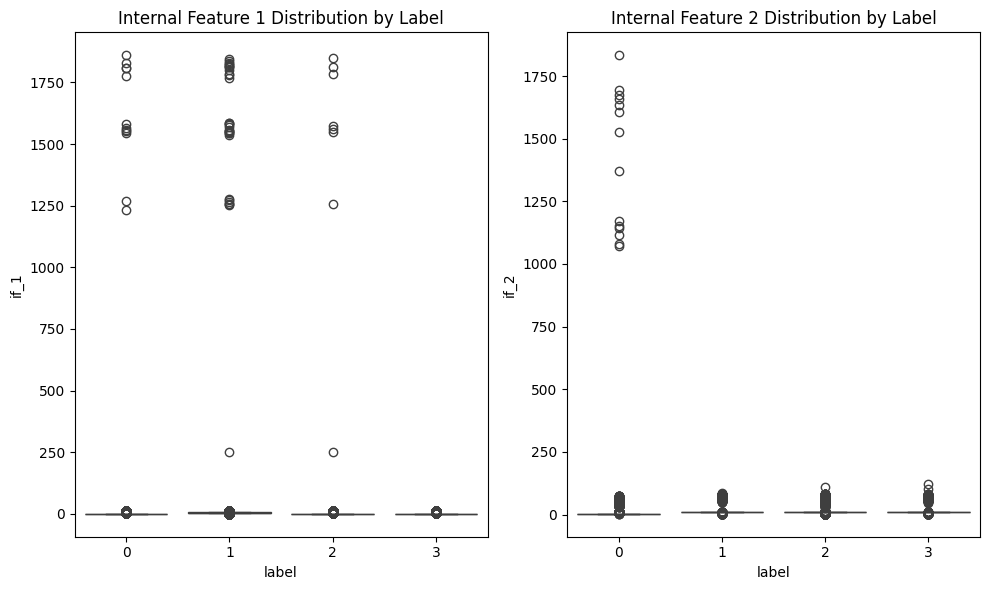

In [14]:
fig,axes = plt.subplots(1,2,figsize=(10,6))
sns.boxplot(data=train,x='label',y='if_1',ax=axes[0])
axes[0].set_title("Internal Feature 1 Distribution by Label")
sns.boxplot(data=train,x='label',y='if_2',ax=axes[1])
axes[1].set_title("Internal Feature 2 Distribution by Label")
plt.tight_layout()
plt.show()

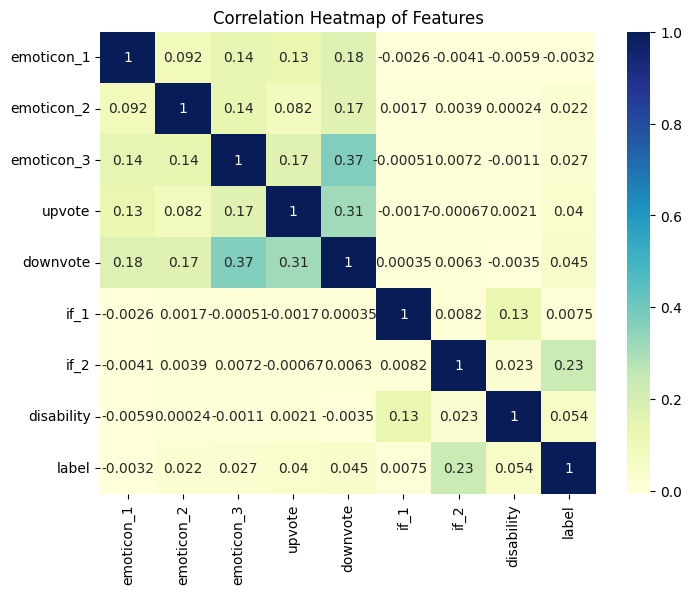

In [15]:
plt.figure(figsize=(8,6))
correlation_matrix = train.corr(numeric_only=True)
sns.heatmap(correlation_matrix,annot=True,cmap='YlGnBu')
plt.title("Correlation Heatmap of Features")
plt.show()

In [16]:
def clean_existing_columns(df):
    df = df.copy()
    df['comment'] = df['comment'].fillna("")
    df['shout_ratio'] = df['comment'].apply(lambda x: sum(1 for c in x if c.isupper())/(len(x)+1))
    df['comment_len'] = df['comment'].str.len()
    df['disability'] = df['disability'].fillna(0).astype(int)
    cols_to_fill = ['race', 'religion', 'gender']
    for col in cols_to_fill:
        df[col] = df[col].fillna('not_detected').astype(str)
    return df

train_clean = clean_existing_columns(train)
test_clean = clean_existing_columns(test)

In [17]:
numeric_cols = ['upvote', 'downvote', 'if_1', 'if_2', 'emoticon_1', 'emoticon_2', 'emoticon_3', 'disability', 'shout_ratio', 'comment_len']
categorical_cols = ['race', 'religion', 'gender']

In [18]:
from sklearn.model_selection import train_test_split,RandomizedSearchCV,cross_val_score

X = train_clean.drop('label', axis=1)
y = train_clean['label']
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [19]:
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, MinMaxScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report,f1_score

In [20]:
text_pipeline = Pipeline([
    ('union', FeatureUnion([
        (
            'word', TfidfVectorizer(
            ngram_range=(1,3),
            max_features=80000,
            sublinear_tf=True,
            strip_accents='unicode',
            min_df=3
        )),
        (
            'char', TfidfVectorizer(
            analyzer='char', 
            ngram_range=(3,7), 
            max_features=60000, 
            sublinear_tf=True, 
            strip_accents='unicode',
            min_df=3
        ))
]))
])

In [21]:
preprocessor_pipeline = Pipeline([
    ('preprocessor', ColumnTransformer([
        ('text', text_pipeline, 'comment'),
        ('num', StandardScaler(), numeric_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ]))
])

In [22]:
custom_weights = {0:1,1:3.4,2:1.7,3:6}

lr_model = Pipeline([
    ('prep',preprocessor_pipeline),
    ('clf',LogisticRegression(
        solver='lbfgs',
        max_iter=4000,
        random_state=42,
        class_weight=custom_weights
    ))
])

In [23]:
lr_model.fit(X_train, y_train)

Pipeline(steps=[('prep',
                 Pipeline(steps=[('preprocessor',
                                  ColumnTransformer(transformers=[('text',
                                                                   Pipeline(steps=[('union',
                                                                                    FeatureUnion(transformer_list=[('word',
                                                                                                                    TfidfVectorizer(max_features=80000,
                                                                                                                                    min_df=3,
                                                                                                                                    ngram_range=(1,
                                                                                                                                                 3),
                                                                                                                                    strip_accents='unicode',
                                                                                                                                    sublinear_tf=True)),
                                                                                                                   ('char',
                                                                                                                    TfidfVectorizer(analyzer='char',
                                                                                                                                    max_features=60000,
                                                                                                                                    min_df=3,
                                                                                                                                    ngram_range=(3,
                                                                                                                                                 7...
                                                                                                                                    sublinear_tf=True))]))]),
                                                                   'comment'),
                                                                  ('num',
                                                                   StandardScaler(),
                                                                   ['upvote',
                                                                    'downvote',
                                                                    'if_1',
                                                                    'if_2',
                                                                    'emoticon_1',
                                                                    'emoticon_2',
                                                                    'emoticon_3',
                                                                    'disability',
                                                                    'shout_ratio',
                                                                    'comment_len']),
                                                                  ('cat',
                                                                   OneHotEncoder(handle_unknown='ignore'),
                                                                   ['race',
                                                                    'religion',
                                                                    'gender'])]))])),
                ('clf',
                 LogisticRegression(class_weight={0: 1, 1: 3.4, 2: 1.7, 3: 6},
                                    max_iter=4000, random_state=42))])

In [24]:
pred_lr = lr_model.predict(X_val)
print(f1_score(y_val,pred_lr,average='macro'))
print(classification_report(y_val,pred_lr))

0.8162502130150844
              precision    recall  f1-score   support

           0       0.98      0.93      0.95     22835
           1       0.73      0.80      0.76      3183
           2       0.86      0.91      0.88     12488
           3       0.66      0.67      0.66      1094

    accuracy                           0.91     39600
   macro avg       0.81      0.83      0.82     39600
weighted avg       0.91      0.91      0.91     39600



In [25]:
from sklearn.ensemble import VotingClassifier, StackingClassifier

In [26]:
from sklearn.neural_network import MLPClassifier

mlp_model = Pipeline([
    ('prep',preprocessor_pipeline),
    ('clf',MLPClassifier(
        hidden_layer_sizes = (64,),
        activation = 'relu',
        solver = 'adam',
        alpha = 0.1,
        batch_size=512,           
        learning_rate='constant',
        learning_rate_init=0.0005,
        max_iter=20,
        n_iter_no_change=2,
        early_stopping=True,
        validation_fraction=0.1,
        random_state=42,
        verbose=True
    ))
])

In [27]:
mlp_model.fit(X_train,y_train)

Iteration 1, loss = 0.75682610
Validation score: 0.818813
Iteration 2, loss = 0.49275126
Validation score: 0.875316
Iteration 3, loss = 0.39246278
Validation score: 0.900126
Iteration 4, loss = 0.34796674
Validation score: 0.905682
Iteration 5, loss = 0.32701801
Validation score: 0.906818
Iteration 6, loss = 0.31540745
Validation score: 0.909722
Iteration 7, loss = 0.30722435
Validation score: 0.907197
Iteration 8, loss = 0.30096720
Validation score: 0.909217
Iteration 9, loss = 0.29498997
Validation score: 0.909533
Validation score did not improve more than tol=0.000100 for 2 consecutive epochs. Stopping.


Pipeline(steps=[('prep',
                 Pipeline(steps=[('preprocessor',
                                  ColumnTransformer(transformers=[('text',
                                                                   Pipeline(steps=[('union',
                                                                                    FeatureUnion(transformer_list=[('word',
                                                                                                                    TfidfVectorizer(max_features=80000,
                                                                                                                                    min_df=3,
                                                                                                                                    ngram_range=(1,
                                                                                                                                                 3),
                                                                                                                                    strip_accents='unicode',
                                                                                                                                    sublinear_tf=True)),
                                                                                                                   ('char',
                                                                                                                    TfidfVectorizer(analyzer='char',
                                                                                                                                    max_features=60000,
                                                                                                                                    min_df=3,
                                                                                                                                    ngram_range=(3,
                                                                                                                                                 7...
                                                                    'if_2',
                                                                    'emoticon_1',
                                                                    'emoticon_2',
                                                                    'emoticon_3',
                                                                    'disability',
                                                                    'shout_ratio',
                                                                    'comment_len']),
                                                                  ('cat',
                                                                   OneHotEncoder(handle_unknown='ignore'),
                                                                   ['race',
                                                                    'religion',
                                                                    'gender'])]))])),
                ('clf',
                 MLPClassifier(alpha=0.1, batch_size=512, early_stopping=True,
                               hidden_layer_sizes=(64,),
                               learning_rate_init=0.0005, max_iter=20,
                               n_iter_no_change=2, random_state=42,
                               verbose=True))])

In [28]:
pred_mlp = mlp_model.predict(X_val)
print(f1_score(y_val,pred_mlp,average='macro'))
print(classification_report(y_val,pred_mlp))

0.7973234693517312
              precision    recall  f1-score   support

           0       0.97      0.95      0.96     22835
           1       0.77      0.78      0.77      3183
           2       0.85      0.91      0.88     12488
           3       0.78      0.46      0.58      1094

    accuracy                           0.91     39600
   macro avg       0.84      0.77      0.80     39600
weighted avg       0.91      0.91      0.91     39600



In [29]:
base_models = [
    ("lr",lr_model),
    ("mlp",mlp_model)
]

stk_clf = StackingClassifier(
    estimators = base_models,
    final_estimator = LogisticRegression(),
    stack_method = "predict_proba",
    cv=3,
    n_jobs=-1
)

In [30]:
stk_clf.fit(X_train,y_train)

StackingClassifier(cv=3,
                   estimators=[('lr',
                                Pipeline(steps=[('prep',
                                                 Pipeline(steps=[('preprocessor',
                                                                  ColumnTransformer(transformers=[('text',
                                                                                                   Pipeline(steps=[('union',
                                                                                                                    FeatureUnion(transformer_list=[('word',
                                                                                                                                                    TfidfVectorizer(max_features=80000,
                                                                                                                                                                    min_df=3,
                                                                                                                                                                    ngram_range=(1,
                                                                                                                                                                                 3),
                                                                                                                                                                    strip_accents='unicode',
                                                                                                                                                                    sublinear_tf=True)),
                                                                                                                                                   ('char',
                                                                                                                                                    TfidfVectorizer(analyzer='char',
                                                                                                                                                                    ma...
                                                                                                    'comment_len']),
                                                                                                  ('cat',
                                                                                                   OneHotEncoder(handle_unknown='ignore'),
                                                                                                   ['race',
                                                                                                    'religion',
                                                                                                    'gender'])]))])),
                                                ('clf',
                                                 MLPClassifier(alpha=0.1,
                                                               batch_size=512,
                                                               early_stopping=True,
                                                               hidden_layer_sizes=(64,),
                                                               learning_rate_init=0.0005,
                                                               max_iter=20,
                                                               n_iter_no_change=2,
                                                               random_state=42,
                                                               verbose=True))]))],
                   final_estimator=LogisticRegression(), n_jobs=-1,
                   stack_method='predict_proba')

In [31]:
pred_stk = stk_clf.predict(X_val)
print(f1_score(y_val,pred_stk,average='macro'))
print(classification_report(y_val,pred_stk))

0.8188900329722263
              precision    recall  f1-score   support

           0       0.97      0.95      0.96     22835
           1       0.78      0.77      0.77      3183
           2       0.86      0.91      0.89     12488
           3       0.72      0.61      0.66      1094

    accuracy                           0.91     39600
   macro avg       0.83      0.81      0.82     39600
weighted avg       0.91      0.91      0.91     39600



In [32]:
test_pred = stk_clf.predict(test_clean)

Iteration 1, loss = 0.75682610
Validation score: 0.818813
Iteration 2, loss = 0.49275126
Validation score: 0.875316
Iteration 3, loss = 0.39246278
Validation score: 0.900126
Iteration 4, loss = 0.34796674
Validation score: 0.905682
Iteration 5, loss = 0.32701801
Validation score: 0.906818
Iteration 6, loss = 0.31540745
Validation score: 0.909722
Iteration 7, loss = 0.30722435
Validation score: 0.907197
Iteration 8, loss = 0.30096720
Validation score: 0.909217
Iteration 9, loss = 0.29498997
Validation score: 0.909533
Validation score did not improve more than tol=0.000100 for 2 consecutive epochs. Stopping.
Iteration 1, loss = 0.82917136
Validation score: 0.783807
Iteration 1, loss = 0.82186928
Validation score: 0.789867
Iteration 1, loss = 0.83487836
Validation score: 0.770360
Iteration 2, loss = 0.56936667
Validation score: 0.848769
Iteration 2, loss = 0.54790863
Validation score: 0.856250
Iteration 2, loss = 0.58538068
Validation score: 0.840246
Iteration 3, loss = 0.45485356
Validat

In [33]:
sample = pd.read_csv("/kaggle/input/comment-category-prediction-challenge/Sample.csv")
submission = sample.copy()
submission['label'] = test_pred
submission.to_csv('/kaggle/working/submission.csv',index=False)